In [1]:
%pip install -q yfinance


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/miniconda3/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide TensorFlow startup logs
warnings.filterwarnings("ignore")           # hide library version warnings

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [4]:
# figure colors: actual data, AR, NN, reference lines
c_actual, c_ar, c_nn, c_ref = "#52514e", "#eb6834", "#2a78d6", "#898781"

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [5]:
tickers = ["AAPL", "AMZN", "GOOGL", "JNJ", "JPM", "KO", "MSFT", "NVDA", "WMT", "XOM"]

data = yf.download(tickers, start="2010-01-01", end="2026-11-21")


[                       0%                       ]
[                       0%                       ]


[**************        30%                       ]  3 of 10 completed
[**************        30%                       ]  3 of 10 completed


[**********************50%                       ]  5 of 10 completed


[**********************60%****                   ]  6 of 10 completed


[**********************70%*********              ]  7 of 10 completed
[**********************70%*********              ]  7 of 10 completed


[**********************90%******************     ]  9 of 10 completed


[*********************100%***********************]  10 of 10 completed

In [109]:
data

Price            Close                                                  \
Ticker            AAPL        AMZN       GOOGL         JNJ         JPM   
Date                                                                     
2010-01-04    6.396100    6.695000   15.536592   39.778629   28.012629   
2010-01-05    6.407158    6.734500   15.468175   39.317379   28.555237   
2010-01-06    6.305246    6.612500   15.078241   39.637173   28.712118   
2010-01-07    6.293588    6.500000   14.727226   39.354279   29.280855   
2010-01-08    6.335430    6.676000   14.923558   39.489582   29.208960   
...                ...         ...         ...         ...         ...   
2026-11-16  352.779999  257.750000  283.720001  282.549988  338.209991   
2026-11-17  351.910004  257.890015  280.200012  278.700012  329.959991   
2026-11-18  352.450012  267.739990  282.440002  272.700012  324.109985   
2026-11-19  349.209991  257.369995  272.660004  267.140015  320.220001   
2026-11-20  342.559998  246.820007  265.290009  270.470001  310.529999   

Price                                                                  ...  \
Ticker             KO        MSFT        NVDA         WMT         XOM  ...   
Date                                                                   ...   
2010-01-04  17.103193   22.939920    0.422817   12.878354   36.903877  ...   
2010-01-05  16.896299   22.947340    0.428992   12.750123   37.047974  ...   
2010-01-06  16.890301   22.806509    0.431736   12.721622   37.368176  ...   
2010-01-07  16.848326   22.569324    0.423275   12.728747   37.250755  ...   
2010-01-08  16.536478   22.724983    0.424189   12.664629   37.101322  ...   
...               ...         ...         ...         ...         ...  ...   
2026-11-16  99.480003  516.991272  156.139999  128.410004  166.869995  ...   
2026-11-17  98.790001  505.263947  155.460007  127.519997  167.210007  ...   
2026-11-18  98.089996  507.309998  150.960007  127.360001  160.580002  ...   
2026-11-19  96.089996  498.299988  145.979996  126.040001  158.929993  ...   
2026-11-20  96.989998  484.519989  125.529999  127.949997  159.990005  ...   

Price          Volume                                                      \
Ticker           AAPL       AMZN      GOOGL       JNJ       JPM        KO   
Date                                                                        
2010-01-04  493729600  151998000   78169752   9506200  35460500  13870400   
2010-01-05  601904800  177038000  120067812  10673100  41208300  23172400   
2010-01-06  552160000  143576000  158988852  13171500  27729000  19264600   
2010-01-07  477131200  220604000  256315428  10901600  44864700  13234600   
2010-01-08  447610800  196610000  188783028   7898000  33110100  28712400   
...               ...        ...        ...       ...       ...       ...   
2026-11-16   50292200   48054200   34747200   8101700   7250300  19154600   
2026-11-17   37407500   38685200   32175900   8973500   8210200  19066200   
2026-11-18   34209900   41289500   27401800   7935200   6778200  16554000   
2026-11-19   40906900   53117900   49718500   9836200   6968100  23048400   
2026-11-20   80692500   74362600   58330600  11919300  12517400  26046900   

Price                                                
Ticker          MSFT       NVDA       WMT       XOM  
Date                                                 
2010-01-04  38409100  800204000  62259300  27809100  
2010-01-05  49749600  728648000  46945200  30174700  
2010-01-06  58182400  649168000  37551600  35044700  
2010-01-07  50559700  547792000  31988100  27192100  
2010-01-08  51197400  478168000  34089600  24891800  
...              ...        ...       ...       ...  
2026-11-16  30218600  333822100  17780200  14286200  
2026-11-17  27992800  406985100  19841300  11955200  
2026-11-18  22050100  349791400  27962700  18122000  
2026-11-19  29350600  322940100  32289300  12263500  
2026-11-20  47200000  633418400  42651200  18684400  

[4248 rows x 50 columns]

In [6]:
close = data["Close"]
volume = data["Volume"]

In [7]:
close

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-04,6.396099,6.695000,15.536593,39.778622,28.012625,17.103193,22.939926,0.422817,12.878359,36.903877
2010-01-05,6.407158,6.734500,15.468174,39.317379,28.555214,16.896301,22.947336,0.428991,12.750120,37.047958
2010-01-06,6.305243,6.612500,15.078241,39.637177,28.712124,16.890306,22.806513,0.431736,12.721622,37.368172
2010-01-07,6.293587,6.500000,14.727225,39.354271,29.280870,16.848326,22.569332,0.423275,12.728754,37.250767
2010-01-08,6.335430,6.676000,14.923556,39.489582,29.208973,16.536480,22.724976,0.424189,12.664626,37.101334
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,352.779999,257.750000,283.720001,282.549988,338.209991,99.480003,516.991272,156.139999,128.410004,166.869995
2026-11-17,351.910004,257.890015,280.200012,278.700012,329.959991,98.790001,505.263947,155.460007,127.519997,167.210007
2026-11-18,352.450012,267.739990,282.440002,272.700012,324.109985,98.089996,507.309998,150.960007,127.360001,160.580002


In [111]:
volume

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-04,493729600,151998000,78169752,9506200,35460500,13870400,38409100,800204000,62259300,27809100
2010-01-05,601904800,177038000,120067812,10673100,41208300,23172400,49749600,728648000,46945200,30174700
2010-01-06,552160000,143576000,158988852,13171500,27729000,19264600,58182400,649168000,37551600,35044700
2010-01-07,477131200,220604000,256315428,10901600,44864700,13234600,50559700,547792000,31988100,27192100
2010-01-08,447610800,196610000,188783028,7898000,33110100,28712400,51197400,478168000,34089600,24891800
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,50292200,48054200,34747200,8101700,7250300,19154600,30218600,333822100,17780200,14286200
2026-11-17,37407500,38685200,32175900,8973500,8210200,19066200,27992800,406985100,19841300,11955200
2026-11-18,34209900,41289500,27401800,7935200,6778200,16554000,22050100,349791400,27962700,18122000


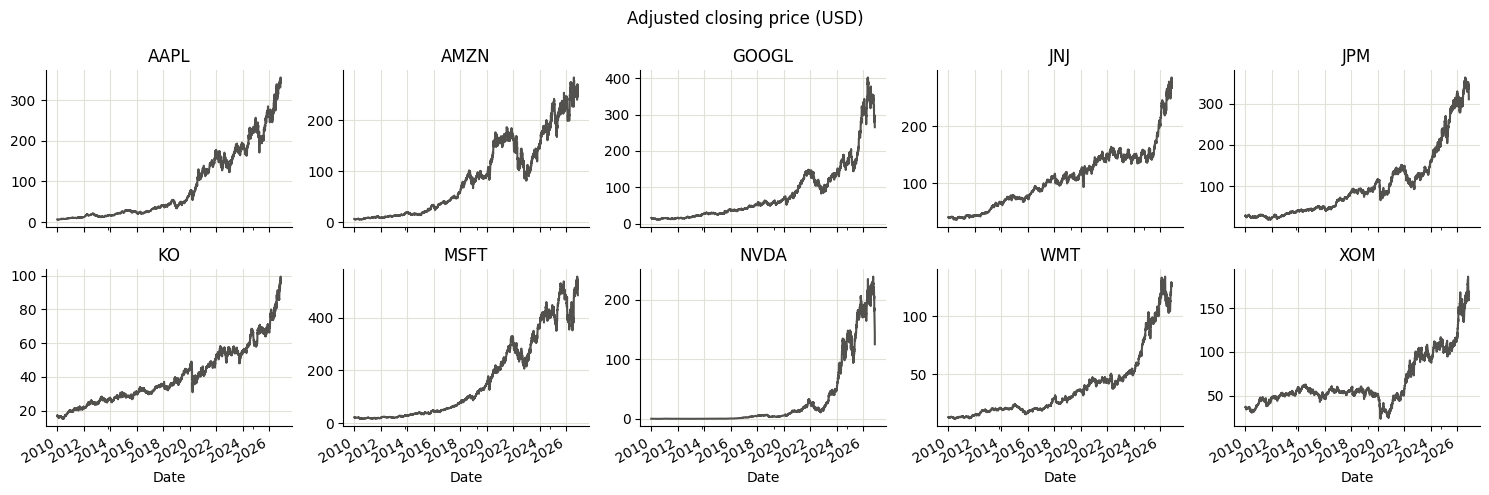

In [9]:
close.plot(subplots=True, layout=(2, 5), figsize=(15, 5), legend=False,
           title=tickers, color=c_actual)
plt.suptitle("Adjusted closing price (USD)")
plt.tight_layout()
plt.show()

### 2. Features

In [10]:
daily_return = close.pct_change().dropna()            # daily return
volume_change = np.log(volume).diff().dropna()        # daily change in log volume

In [11]:
daily_return

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.001729,0.005900,-0.004404,-0.011595,0.019369,-0.012097,0.000323,0.014603,-0.009958,0.003904
2010-01-06,-0.015906,-0.018116,-0.025209,0.008134,0.005495,-0.000355,-0.006137,0.006397,-0.002235,0.008643
2010-01-07,-0.001849,-0.017013,-0.023280,-0.007137,0.019809,-0.002485,-0.010400,-0.019597,0.000561,-0.003142
2010-01-08,0.006648,0.027077,0.013331,0.003438,-0.002455,-0.018509,0.006896,0.002161,-0.005038,-0.004012
2010-01-11,-0.008821,-0.024041,-0.001511,0.000155,-0.003357,0.020309,-0.012720,-0.014017,0.016502,0.011220
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,-0.009796,-0.033413,-0.040741,-0.011199,-0.023051,0.002317,-0.011243,-0.041204,0.002498,-0.015632
2026-11-17,-0.002466,0.000543,-0.012407,-0.013626,-0.024393,-0.006936,-0.022684,-0.004355,-0.006931,0.002038
2026-11-18,0.001535,0.038194,0.007994,-0.021529,-0.017729,-0.007086,0.004049,-0.028946,-0.001255,-0.039651


In [12]:
volume_change

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.198111,0.152497,0.429174,0.115782,0.150220,0.513205,0.258708,-0.093676,-0.282327,0.081641
2010-01-06,-0.086261,-0.209500,0.280777,0.210329,-0.396161,-0.184693,0.156580,-0.115499,-0.223265,0.149621
2010-01-07,-0.146046,0.429505,0.477575,-0.189146,0.481172,-0.375435,-0.140428,-0.169796,-0.160352,-0.253698
2010-01-08,-0.063867,-0.115147,-0.305810,-0.322300,-0.303813,0.774494,0.012534,-0.135934,0.063628,-0.088388
2010-01-11,0.032138,-0.113082,0.423152,0.009790,-0.037900,-0.002441,0.294856,0.151906,0.207798,0.209236
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.228283,0.433563,0.120630,0.254386,0.546244,0.060079,0.143111,-0.091469,0.066336,0.219149
2026-11-17,-0.295979,-0.216872,-0.076881,0.102202,0.124334,-0.004626,-0.076510,0.198168,0.109680,-0.178128
2026-11-18,-0.089356,0.065151,-0.160609,-0.122967,-0.191666,-0.141289,-0.238630,-0.151440,0.343106,0.415960


In [13]:
daily_return.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,4247.0,0.001094,0.017675,-0.128647,-0.007410,0.000998,0.010258,0.153288
AMZN,4247.0,0.001065,0.020778,-0.140494,-0.009232,0.000857,0.012047,0.157457
GOOGL,4247.0,0.000824,0.017671,-0.126412,-0.007752,0.000852,0.009555,0.162584
JNJ,4247.0,0.000510,0.010833,-0.100379,-0.004594,0.000393,0.005960,0.079977
JPM,4247.0,0.000715,0.017239,-0.149649,-0.007483,0.000702,0.009125,0.180125
KO,4247.0,0.000468,0.010834,-0.096725,-0.004744,0.000496,0.005952,0.064796
MSFT,4247.0,0.000853,0.016449,-0.147390,-0.007234,0.000683,0.009191,0.155067
NVDA,4247.0,0.001750,0.028689,-0.187558,-0.012680,0.001639,0.016308,0.298067
WMT,4247.0,0.000620,0.012626,-0.113758,-0.005338,0.000692,0.006599,0.117085


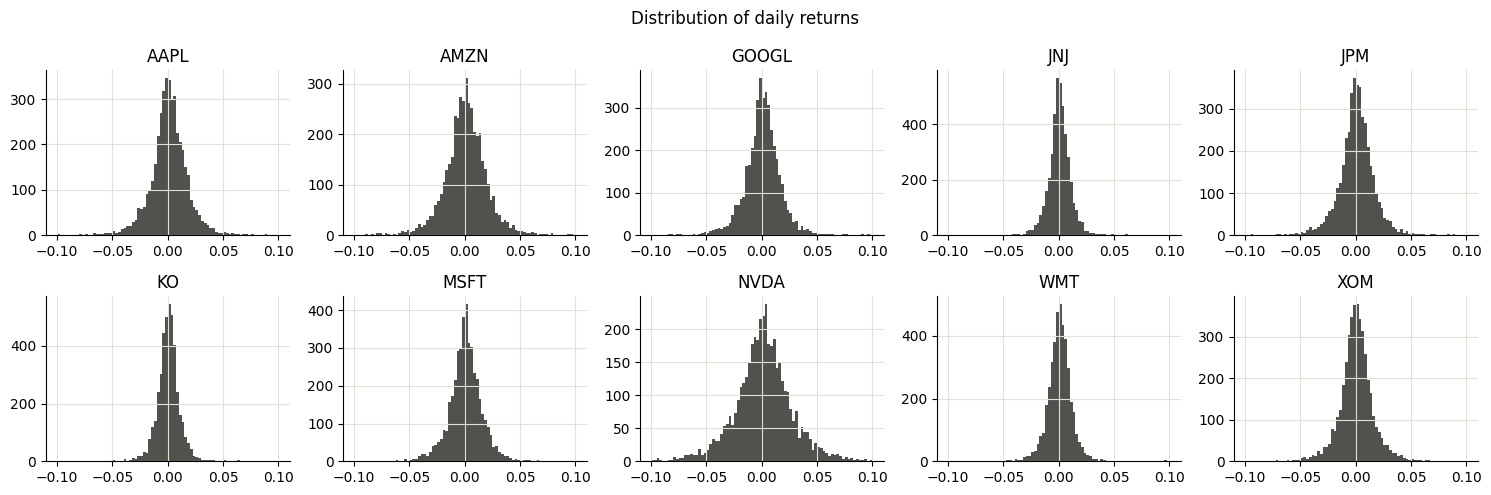

In [14]:
daily_return.hist(bins=80, range=(-0.1, 0.1), layout=(2, 5), figsize=(15, 5), color=c_actual)
plt.suptitle("Distribution of daily returns")
plt.tight_layout()
plt.show()

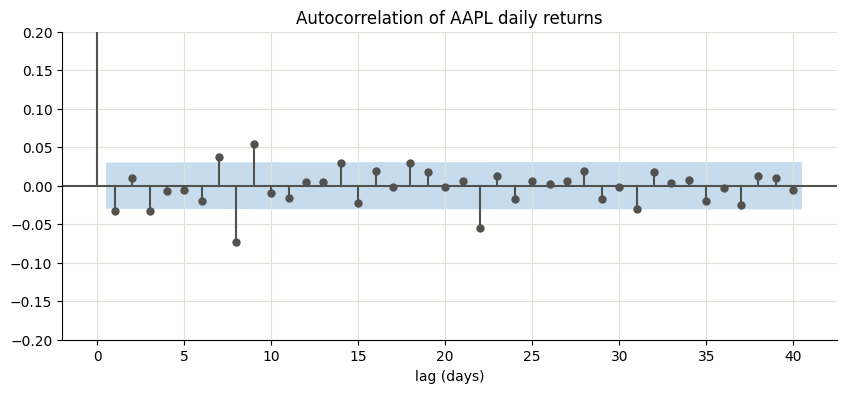

In [15]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(daily_return["AAPL"], lags=40, color=c_actual, vlines_kwargs={"colors": c_actual},
         title="Autocorrelation of AAPL daily returns")
plt.xlabel("lag (days)")
plt.ylim(-0.2, 0.2)
plt.show()

In [16]:
# overnight gap: today's open against yesterday's close
overnight_gap = (data["Open"] / close.shift(1) - 1).loc[daily_return.index]

In [17]:
overnight_gap

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,2.757005e-03,-0.003510,0.000686,-0.001546,-0.001401,-3.330910e-03,-0.003231,-0.003786,-2.581705e-03,0.000578
2010-01-06,-8.729851e-08,-0.000668,0.002997,-0.000469,-0.005265,6.568586e-08,-0.002584,-0.000533,-3.538939e-03,0.000432
2010-01-07,3.697287e-03,-0.001815,0.001874,-0.003103,-0.002960,-8.252794e-08,-0.004550,-0.005297,2.800699e-03,-0.001714
2010-01-08,-1.329531e-03,0.004308,-0.003535,-0.001094,-0.009377,-1.299206e-02,-0.005583,-0.008104,-3.172394e-03,-0.001576
2010-01-11,3.868336e-03,-0.006741,0.004053,0.008410,0.009848,3.528086e-07,0.001631,0.005391,5.506718e-07,0.006042
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,2.413944e-03,-0.015975,-0.006627,0.011339,-0.001791,7.657452e-03,0.002310,-0.023519,1.358424e-02,0.000059
2026-11-17,1.416968e-04,-0.000776,-0.001128,-0.012600,-0.013719,-6.936092e-03,-0.006602,0.004867,-7.086704e-03,0.003536
2026-11-18,8.524560e-05,0.007445,0.009101,-0.011303,-0.007395,-8.300432e-03,-0.001462,0.023993,-8.469214e-03,-0.007715


In [18]:
# market-wide series: S&P 500 index, VIX volatility index, 10-year Treasury yield
market = yf.download(["^GSPC", "^VIX", "^TNX"], start="2010-01-01", end="2026-11-21")["Close"]
market = market.reindex(close.index).ffill()      # same trading days as the stocks


[                       0%                       ]


[**********************67%*******                ]  2 of 3 completed


[*********************100%***********************]  3 of 3 completed

In [19]:
market

Ticker,^GSPC,^TNX,^VIX
Date,,,
2010-01-04,1132.989990,3.841,20.040001
2010-01-05,1136.520020,3.755,19.350000
2010-01-06,1137.140015,3.808,19.160000
2010-01-07,1141.689941,3.822,19.059999
2010-01-08,1144.979980,3.808,18.129999
...,...,...,...
2026-11-16,7416.589844,5.121,22.910000
2026-11-17,7340.529785,5.103,25.459999
2026-11-18,7323.629883,5.066,24.559999


In [20]:
sp500_return = market["^GSPC"].pct_change()       # daily return of the S&P 500
vix_level = np.log(market["^VIX"])                # log of the VIX
rate_change = market["^TNX"].diff()               # daily change in the 10-year yield

In [21]:
# the market series are the same for every company, so copy each into one column per ticker
sp500_return = pd.DataFrame({t: sp500_return for t in tickers}).loc[daily_return.index]
vix_level = pd.DataFrame({t: vix_level for t in tickers}).loc[daily_return.index]
rate_change = pd.DataFrame({t: rate_change for t in tickers}).loc[daily_return.index]

In [22]:
vix_level

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,2.962692,2.962692,2.962692,2.962692,2.962692,2.962692,2.962692,2.962692,2.962692,2.962692
2010-01-06,2.952825,2.952825,2.952825,2.952825,2.952825,2.952825,2.952825,2.952825,2.952825,2.952825
2010-01-07,2.947592,2.947592,2.947592,2.947592,2.947592,2.947592,2.947592,2.947592,2.947592,2.947592
2010-01-08,2.897568,2.897568,2.897568,2.897568,2.897568,2.897568,2.897568,2.897568,2.897568,2.897568
2010-01-11,2.865054,2.865054,2.865054,2.865054,2.865054,2.865054,2.865054,2.865054,2.865054,2.865054
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,3.131573,3.131573,3.131573,3.131573,3.131573,3.131573,3.131573,3.131573,3.131573,3.131573
2026-11-17,3.237109,3.237109,3.237109,3.237109,3.237109,3.237109,3.237109,3.237109,3.237109,3.237109
2026-11-18,3.201119,3.201119,3.201119,3.201119,3.201119,3.201119,3.201119,3.201119,3.201119,3.201119


In [23]:
# earnings reports: 1 on the day the market reacts, and the percent surprise against the analyst estimate
earnings_day = pd.DataFrame(0.0, index=daily_return.index, columns=tickers)
earnings_surprise = pd.DataFrame(0.0, index=daily_return.index, columns=tickers)

In [24]:
for t in tickers:
    earnings = yf.Ticker(t).get_earnings_dates(limit=100).sort_index()
    earnings = earnings["2010-01-05":"2026-11-20"]
    for when, row in earnings.iterrows():
        day = when.tz_localize(None).normalize()
        if when.hour >= 16:
            day = day + pd.Timedelta(days=1)             # reported after the close: the market reacts the next day
        i = daily_return.index.searchsorted(day)         # first trading day on or after that date
        earnings_day.loc[daily_return.index[i], t] = 1
        earnings_surprise.loc[daily_return.index[i], t] = row["Surprise(%)"]

In [25]:
earnings_day.sum()      # number of earnings days per company

AAPL     68.0
AMZN     68.0
GOOGL    68.0
JNJ      68.0
JPM      68.0
KO       68.0
MSFT     68.0
NVDA     68.0
WMT      68.0
XOM      68.0
dtype: float64

In [26]:
earnings_surprise = earnings_surprise.fillna(0).clip(-50, 50)      # cap the surprise at 50 percent

In [27]:
# ex-dividend days
ex_dividend_day = pd.DataFrame(0.0, index=daily_return.index, columns=tickers)

for t in tickers:
    dividends = yf.Ticker(t).dividends["2010-01-05":"2026-11-20"]
    ex_dividend_day.loc[dividends.index.tz_localize(None).normalize(), t] = 1

In [28]:
ex_dividend_day.sum()

AAPL     58.0
AMZN      0.0
GOOGL    10.0
JNJ      67.0
JPM      67.0
KO       67.0
MSFT     68.0
NVDA     56.0
WMT      67.0
XOM      68.0
dtype: float64

In [29]:
# both dates are announced in advance, so the row for one day can say what the next day is
earnings_tomorrow = earnings_day.shift(-1).fillna(0)
ex_dividend_tomorrow = ex_dividend_day.shift(-1).fillna(0)

### 3. Train, validation, and test sets

In [30]:
train_start, train_end = "2010-06-01", "2022-12-31"
val_start, val_end = "2023-01-01", "2023-12-31"
test_start, test_end = "2024-01-01", "2026-11-20"

In [31]:
# standardize with training-period statistics only
daily_return_mean = daily_return[:train_end].mean()
daily_return_std = daily_return[:train_end].std()
volume_change_mean = volume_change[:train_end].mean()
volume_change_std = volume_change[:train_end].std()

scaled_return = (daily_return - daily_return_mean) / daily_return_std
scaled_volume_change = (volume_change - volume_change_mean) / volume_change_std

In [32]:
scaled_return

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.035928,0.235993,-0.298099,-1.138740,1.043660,-1.133182,-0.031699,0.467489,-0.846876,0.218087
2010-01-06,-0.938983,-0.918157,-1.519835,0.721871,0.271700,-0.070955,-0.426206,0.175283,-0.219094,0.514939
2010-01-07,-0.161846,-0.865179,-1.406554,-0.718326,1.068093,-0.263708,-0.686544,-0.750351,0.008172,-0.223282
2010-01-08,0.307881,1.253730,0.743356,0.279049,-0.170651,-1.713271,0.369733,0.024459,-0.446950,-0.277761
2010-01-11,-0.547316,-1.202938,-0.128249,-0.030552,-0.220824,1.798353,-0.828244,-0.551618,1.304041,0.676354
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,-0.601186,-1.653342,-2.431948,-1.101338,-1.316561,0.170786,-0.738050,-1.519732,0.165692,-1.005693
2026-11-17,-0.195984,-0.021441,-0.768050,-1.330241,-1.391238,-0.666330,-1.436745,-0.207579,-0.600830,0.101159
2026-11-18,0.025176,1.788022,0.429955,-2.075533,-1.020478,-0.679872,0.195878,-1.083260,-0.139394,-2.510220


In [33]:
def standardize(feature):
    return (feature - feature[:train_end].mean()) / feature[:train_end].std()

In [34]:
scaled_gap = standardize(overnight_gap)
scaled_sp500_return = standardize(sp500_return)
scaled_vix = standardize(vix_level)
scaled_rate_change = standardize(rate_change)
scaled_earnings_tomorrow = standardize(earnings_tomorrow)
scaled_surprise = standardize(earnings_surprise)

In [35]:
# ex_dividend_tomorrow stays as 0 and 1: AMZN pays no dividend, so its column cannot be standardized
features = [scaled_return, scaled_volume_change, scaled_gap, scaled_sp500_return, scaled_vix,
            scaled_rate_change, scaled_earnings_tomorrow, scaled_surprise, ex_dividend_tomorrow]

In [36]:
len(features)

9

In [37]:
L = 60      # days of history in each sample

def make_windows(features, target, start, end):
    rows = target.index.get_indexer(target[start:end].index)    # row numbers of the days to predict
    X, y = [], []
    for t in tickers:
        values = np.column_stack([f[t] for f in features])
        for i in rows:
            X.append(values[i - L:i])        # the 60 days before day i
            y.append(target[t].iloc[i])      # the value on day i
    return np.array(X), np.array(y)

In [38]:
X_train, y_train = make_windows(features, scaled_return, train_start, train_end)
X_val, y_val = make_windows(features, scaled_return, val_start, val_end)
X_test, y_test = make_windows(features, scaled_return, test_start, test_end)

In [39]:
X_train.shape, X_val.shape, X_test.shape

((31700, 60, 9), (2500, 60, 9), (7260, 60, 9))

In [40]:
y_train.shape, y_val.shape, y_test.shape

((31700,), (2500,), (7260,))

In [41]:
# number of rows up to the end of each period
n_train = len(daily_return[:train_end])
n_val = len(daily_return[:val_end])
n_all = len(daily_return)

n_train, n_val, n_all

(3271, 3521, 4247)

In [42]:
test_days = daily_return.index[n_val:]

test_days

DatetimeIndex(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05',
               '2024-01-08', '2024-01-09', '2024-01-10', '2024-01-11',
               '2024-01-12', '2024-01-16',
               ...
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16', '2026-11-17', '2026-11-18',
               '2026-11-19', '2026-11-20'],
              dtype='datetime64[s]', name='Date', length=726, freq=None)

### 4. Baseline

In [43]:
actual = daily_return[test_start:test_end]

mse_zero = (actual ** 2).mean()      # error of always predicting a return of zero

In [44]:
mse_zero

Ticker
AAPL     0.000298
AMZN     0.000426
GOOGL    0.000395
JNJ      0.000143
JPM      0.000225
KO       0.000112
MSFT     0.000289
NVDA     0.000941
WMT      0.000219
XOM      0.000224
dtype: float64

### 5. AR model

In [45]:
def lag_matrix(r, p):
    lags = pd.DataFrame({"value": r, "constant": 1.0})
    for i in range(1, p + 1):
        lags[f"Lag {i}"] = lags["value"].shift(i)    # the value i days earlier
    lags = lags.dropna()                              # the first p days have no complete history
    X = np.array(lags.drop(columns="value"))          # 1 for the constant, then Lag 1 ... Lag p
    y = np.array(lags["value"])                       # the value on day i
    return X, y

In [46]:
X_ar, y_ar = lag_matrix(daily_return["AAPL"].to_numpy(), 3)

X_ar[:3], y_ar[:3]      # each row: 1, then the returns 1, 2 and 3 days earlier; y is the return to predict

(array([[ 1.        , -0.00184859, -0.01590641,  0.00172899],
        [ 1.        ,  0.00664843, -0.00184859, -0.01590641],
        [ 1.        , -0.00882145,  0.00664843, -0.00184859]]),
 array([ 0.00664843, -0.00882145, -0.01137499]))

In [47]:
def fit_ar(r, p):
    X, y = lag_matrix(r, p)
    # least squares: the constant first, then one weight per lag
    return np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))

In [48]:
# the constant, then the weights on the returns 1, 2 and 3 days earlier
fit_ar(daily_return["AAPL"].to_numpy()[:n_train], 3)

array([ 0.00117342, -0.04856646, -0.00245401, -0.03072092])

In [49]:
def predict_ar(r, phi, start, end):
    p = len(phi) - 1
    X, y = lag_matrix(r, p)
    return X[start - p:end - p] @ phi      # predictions for days start ... end - 1, each from the p actual values before it

In [50]:
# try several orders: fit on the training period, score on the validation period
orders = [1, 2, 3, 5, 10, 20]
val_mse = pd.DataFrame(index=orders, columns=tickers, dtype=float)

for p in orders:
    for t in tickers:
        r = daily_return[t].to_numpy()
        phi = fit_ar(r[:n_train], p)
        pred = predict_ar(r, phi, n_train, n_val)
        val_mse.loc[p, t] = ((r[n_train:n_val] - pred) ** 2).mean()

In [51]:
val_mse

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
1,0.000164,0.000432,0.000368,0.000111,0.000170,0.000072,0.000253,0.000949,0.000097,0.000249
2,0.000164,0.000432,0.000368,0.000111,0.000168,0.000072,0.000253,0.000953,0.000097,0.000250
3,0.000165,0.000433,0.000368,0.000111,0.000167,0.000072,0.000253,0.000952,0.000097,0.000250
5,0.000165,0.000434,0.000367,0.000111,0.000167,0.000072,0.000254,0.000950,0.000097,0.000251
10,0.000167,0.000433,0.000368,0.000112,0.000168,0.000073,0.000252,0.000953,0.000098,0.000254
20,0.000169,0.000434,0.000368,0.000112,0.000170,0.000075,0.000252,0.000956,0.000102,0.000255


In [52]:
val_zero = (daily_return[val_start:val_end] ** 2).mean()
val_ratio = (val_mse / val_zero).mean(axis=1)      # below 1 beats predicting zero

In [53]:
val_ratio

1     0.999350
2     0.999007
3     0.998791
5     1.001273
10    1.006534
20    1.015903
dtype: float64

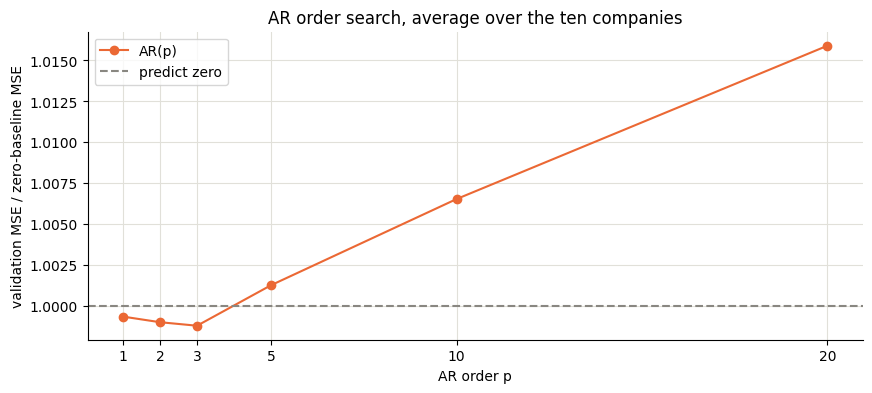

In [54]:
plt.plot(val_ratio, marker="o", color=c_ar, label="AR(p)")
plt.axhline(1.0, color=c_ref, linestyle="--", label="predict zero")
plt.xticks(orders)
plt.xlabel("AR order p")
plt.ylabel("validation MSE / zero-baseline MSE")
plt.title("AR order search, average over the ten companies")
plt.legend()
plt.show()

In [55]:
best_p = val_ratio.idxmin()

best_p

3

In [56]:
# final AR model: fit through the validation period, predict each test day one step ahead
pred_ar = pd.DataFrame(index=test_days, columns=tickers, dtype=float)
coef = pd.DataFrame(columns=tickers, dtype=float)

for t in tickers:
    r = daily_return[t].to_numpy()
    phi = fit_ar(r[:n_val], best_p)
    pred_ar[t] = predict_ar(r, phi, n_val, n_all)
    coef[t] = phi

In [57]:
pred_ar

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.001436,0.001384,0.001118,0.000398,0.000960,0.000213,0.000810,0.001829,0.000392,0.000571
2024-01-03,0.002786,0.001523,0.001265,-0.001004,-0.000564,-0.000065,0.002500,0.003160,-0.000098,0.000538
2024-01-04,0.001806,0.001658,0.000672,0.000472,0.001747,0.000493,0.001259,0.001938,0.000486,0.000506
2024-01-05,0.002771,0.002080,0.001732,0.000498,-0.000408,-0.000094,0.002010,0.001527,0.000984,-0.000503
2024-01-08,0.001634,0.001433,0.000904,0.000107,0.000670,0.000299,0.001195,0.001029,0.000900,-0.000158
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.000490,0.001535,0.000859,0.000166,-0.000397,-0.000538,0.001093,0.001623,-0.000400,-0.000235
2026-11-17,0.001679,0.001844,0.002095,0.001295,0.003370,0.000755,0.002224,0.004107,0.000308,-0.000098
2026-11-18,0.001248,0.001441,0.001444,0.001067,0.001431,-0.000126,0.003649,0.001557,0.000780,-0.000011


In [58]:
coef      # fitted AR coefficients: row 0 is the constant, row k is the weight on the return k days earlier

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
0,0.001212,0.001166,0.000827,0.000453,0.000674,0.000416,0.001050,0.001828,0.000501,0.000406
1,-0.045195,-0.022460,-0.038997,-0.070976,-0.091740,-0.033778,-0.109918,-0.049769,-0.059139,-0.024029
2,-0.003084,-0.006911,0.000937,0.023050,0.055795,0.019293,-0.011195,0.018619,-0.000637,0.008293
3,-0.026883,-0.019401,-0.017418,-0.012067,-0.019780,-0.044202,-0.011903,-0.013878,-0.008557,-0.049900


### 6. Neural network

In [59]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(0)

In [60]:
model = keras.Sequential([
    keras.Input(shape=(60, 9)),
    layers.Flatten(),                               # each 60 x 9 window becomes 540 inputs
    layers.Dense(2048, activation="relu"),
    layers.Dropout(0.3),                            # during training, switch off a random 30% of the nodes
    layers.Dense(1024, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, kernel_initializer="zeros"),    # one output: predicted next-day return, starts at zero
])

In [61]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 540)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │     1,107,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,731,457 (14.23 MB)

 Trainable params: 3,731,457 (14.23 MB)

 Non-trainable params: 0 (0.00 B)

In [62]:
model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.003), loss="mse")

stop = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)

In [63]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=100, batch_size=256, callbacks=[stop], verbose=2)

Epoch 1/100


124/124 - 2s - 19ms/step - loss: 0.9990 - val_loss: 0.8653


Epoch 2/100


124/124 - 1s - 11ms/step - loss: 1.0013 - val_loss: 0.8656


Epoch 3/100


124/124 - 1s - 11ms/step - loss: 0.9956 - val_loss: 0.8695


... (32 outputs left out)

Epoch 20/100


124/124 - 1s - 8ms/step - loss: 0.9895 - val_loss: 0.8792


Epoch 21/100


124/124 - 1s - 8ms/step - loss: 0.9914 - val_loss: 0.8821


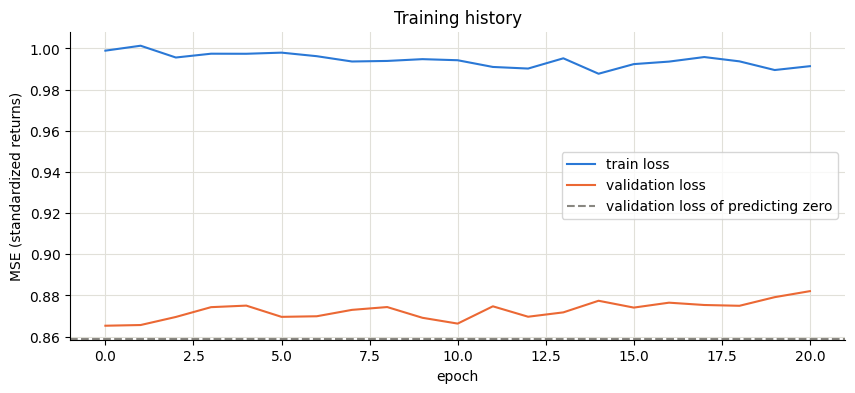

In [64]:
plt.plot(history.history["loss"], color=c_nn, label="train loss")
plt.plot(history.history["val_loss"], color=c_ar, label="validation loss")
plt.axhline((y_val ** 2).mean(), color=c_ref, linestyle="--", label="validation loss of predicting zero")
plt.xlabel("epoch")
plt.ylabel("MSE (standardized returns)")
plt.title("Training history")
plt.legend()
plt.show()

In [65]:
pred_nn = model.predict(X_test, verbose=0).reshape(len(tickers), -1).T
pred_nn = pd.DataFrame(pred_nn, index=test_days, columns=tickers)
pred_nn = pred_nn * daily_return_std + daily_return_mean      # back to raw returns

In [66]:
pred_nn

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,-0.000235,0.000860,0.002339,0.000145,-0.000262,0.000259,0.001233,-0.001522,0.000251,0.001110
2024-01-03,0.002007,0.002222,0.001493,0.000385,-0.000823,0.001210,0.001813,0.003458,0.000925,-0.000044
2024-01-04,0.001063,0.000250,0.000067,-0.000796,0.000459,-0.000142,0.001159,-0.000717,-0.000373,-0.001559
2024-01-05,0.000257,0.000404,0.001337,-0.000439,-0.000687,-0.000766,-0.000624,0.000047,0.000567,-0.000967
2024-01-08,0.001049,0.000857,-0.000106,-0.000515,-0.000139,0.000026,0.001014,0.002583,-0.000408,0.000225
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,-0.002613,-0.001565,0.000677,-0.000749,-0.002419,-0.001308,0.000135,-0.000568,-0.002033,-0.002168
2026-11-17,0.002799,0.006340,0.000991,0.001134,0.002520,-0.000644,0.003178,0.005387,0.000472,-0.000939
2026-11-18,0.001772,0.001946,0.001427,0.001574,0.002462,0.001430,0.003523,0.006583,0.000883,0.000475


### 7. Results

In [67]:
mse_ar = ((actual - pred_ar) ** 2).mean()
mse_nn = ((actual - pred_nn) ** 2).mean()

results = pd.DataFrame({"AR": mse_ar / mse_zero, "NN": mse_nn / mse_zero})

In [68]:
results      # test MSE divided by the zero-baseline MSE, below 1 beats the baseline

,AR,NN
Ticker,,
AAPL,0.999356,1.011527
AMZN,0.998970,0.998835
GOOGL,0.999509,0.986421
JNJ,1.002947,1.002398
JPM,1.000723,1.000788
KO,0.997230,1.009608
MSFT,1.019633,1.005523
NVDA,0.987238,0.995874
WMT,1.002760,1.012975


In [69]:
results.mean()

AR    1.000799
NN    1.003994
dtype: float64

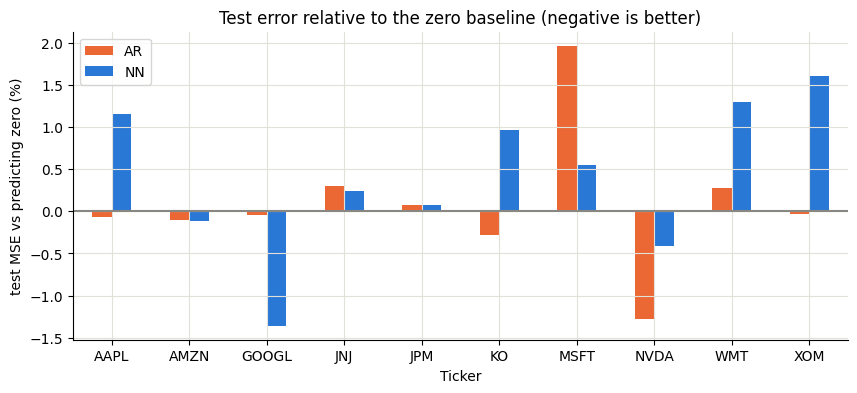

In [70]:
((results - 1) * 100).plot.bar(color=[c_ar, c_nn], figsize=(10, 4))
plt.axhline(0, color=c_ref)
plt.ylabel("test MSE vs predicting zero (%)")
plt.title("Test error relative to the zero baseline (negative is better)")
plt.xticks(rotation=0)
plt.show()

In [71]:
accuracy = pd.DataFrame({
    "always up": (actual > 0).mean(),
    "AR": (np.sign(pred_ar) == np.sign(actual)).mean(),
    "NN": (np.sign(pred_nn) == np.sign(actual)).mean(),
})

In [72]:
accuracy      # share of test days with the correct direction

,always up,AR,NN
AAPL,0.535813,0.517906,0.513774
AMZN,0.515152,0.516529,0.509642
GOOGL,0.539945,0.535813,0.513774
JNJ,0.538567,0.497245,0.523416
JPM,0.561983,0.555096,0.515152
KO,0.517906,0.512397,0.480716
MSFT,0.522039,0.513774,0.493113
NVDA,0.527548,0.533058,0.513774
WMT,0.544077,0.511019,0.476584
XOM,0.538567,0.500000,0.487603


In [73]:
accuracy.mean()

always up    0.534160
AR           0.519284
NN           0.502755
dtype: float64

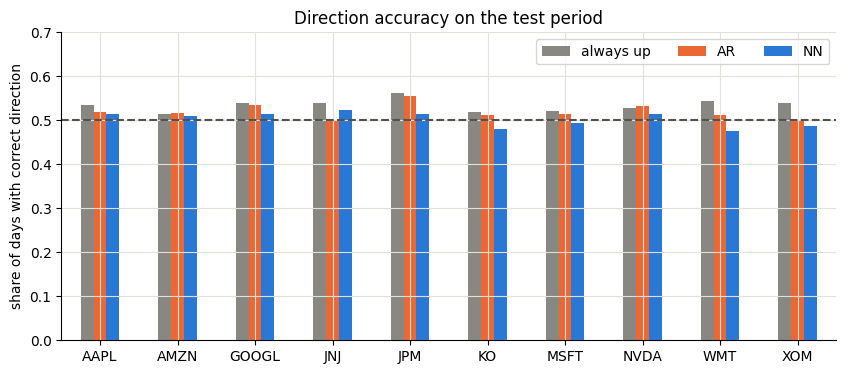

In [74]:
accuracy.plot.bar(color=[c_ref, c_ar, c_nn], figsize=(10, 4))
plt.axhline(0.5, color=c_actual, linestyle="--")
plt.ylim(0, 0.7)
plt.ylabel("share of days with correct direction")
plt.title("Direction accuracy on the test period")
plt.xticks(rotation=0)
plt.legend(ncol=3)
plt.show()

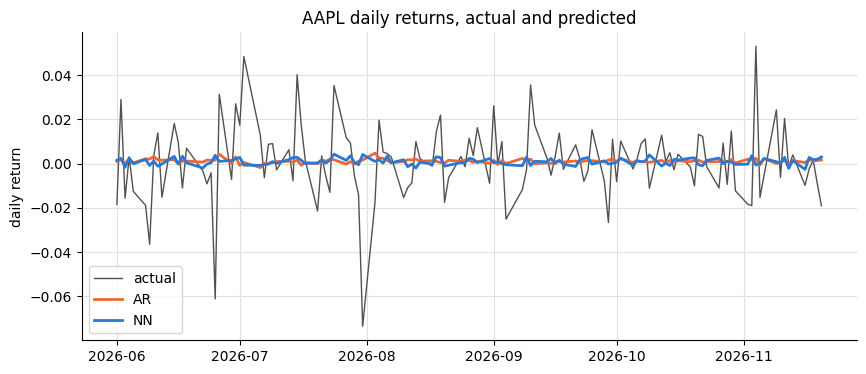

In [75]:
t = "AAPL"

plt.plot(actual[t]["2026-06-01":], color=c_actual, linewidth=1, label="actual")
plt.plot(pred_ar[t]["2026-06-01":], color=c_ar, linewidth=2, label="AR")
plt.plot(pred_nn[t]["2026-06-01":], color=c_nn, linewidth=2, label="NN")
plt.ylabel("daily return")
plt.title("AAPL daily returns, actual and predicted")
plt.legend()
plt.show()

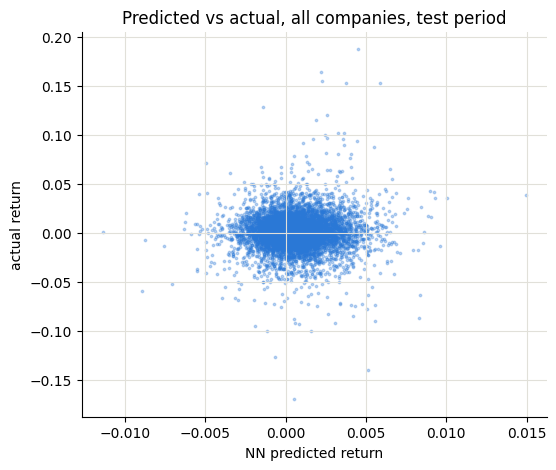

In [76]:
plt.figure(figsize=(6, 5))
plt.scatter(pred_nn.to_numpy().ravel(), actual.to_numpy().ravel(), s=3, alpha=0.3, color=c_nn)
plt.xlabel("NN predicted return")
plt.ylabel("actual return")
plt.title("Predicted vs actual, all companies, test period")
plt.show()

### 8. A second target, the next-day trading range

In [77]:
# daily high-low range as a share of the close
trading_range = ((data["High"] - data["Low"]) / close).loc[daily_return.index]

In [78]:
trading_range

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.010915,0.027248,0.010096,0.012514,0.024267,0.015084,0.014858,0.028785,0.011548,0.009363
2010-01-06,0.021235,0.023289,0.032059,0.011016,0.017760,0.008166,0.018200,0.018538,0.007653,0.017995
2010-01-07,0.014009,0.027077,0.029204,0.009533,0.033713,0.011034,0.016749,0.026472,0.009142,0.009169
2010-01-08,0.013869,0.034826,0.023488,0.009812,0.013876,0.016138,0.020874,0.023181,0.009563,0.007624
2010-01-11,0.021655,0.027550,0.017335,0.011523,0.019762,0.029323,0.021143,0.038272,0.024719,0.012375
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.016498,0.024210,0.039405,0.028030,0.029124,0.014877,0.021487,0.052453,0.015342,0.022772
2026-11-17,0.016169,0.022878,0.020093,0.014926,0.024700,0.010932,0.037788,0.050560,0.014586,0.019377
2026-11-18,0.014045,0.032793,0.018694,0.022516,0.019685,0.017433,0.018415,0.061606,0.021200,0.039918


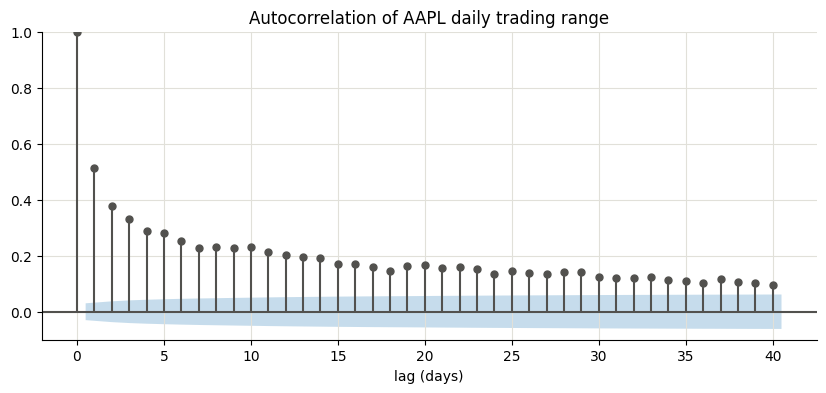

In [79]:
plot_acf(trading_range["AAPL"], lags=40, color=c_actual, vlines_kwargs={"colors": c_actual},
         title="Autocorrelation of AAPL daily trading range")
plt.xlabel("lag (days)")
plt.ylim(-0.1, 1)
plt.show()

In [80]:
trading_range_mean = trading_range[:train_end].mean()
trading_range_std = trading_range[:train_end].std()

scaled_range = (trading_range - trading_range_mean) / trading_range_std

In [81]:
X_train_range, y_train_range = make_windows(features + [scaled_range],
                                            scaled_range, train_start, train_end)
X_val_range, y_val_range = make_windows(features + [scaled_range],
                                        scaled_range, val_start, val_end)
X_test_range, y_test_range = make_windows(features + [scaled_range],
                                          scaled_range, test_start, test_end)

In [82]:
X_train_range.shape, X_val_range.shape, X_test_range.shape

((31700, 60, 10), (2500, 60, 10), (7260, 60, 10))

In [83]:
# baseline: predict the average range of the previous 20 days
pred_avg = trading_range.rolling(20).mean().shift(1)
err_avg = (trading_range - pred_avg) ** 2

val_avg = err_avg[val_start:val_end].mean()
mse_avg = err_avg[test_start:test_end].mean()

In [84]:
mse_avg

Ticker
AAPL     0.000133
AMZN     0.000131
GOOGL    0.000129
JNJ      0.000050
JPM      0.000103
KO       0.000038
MSFT     0.000081
NVDA     0.000342
WMT      0.000070
XOM      0.000074
dtype: float64

In [85]:
# AR order search: fit on the training period, score on the validation period
val_mse_range = pd.DataFrame(index=orders, columns=tickers, dtype=float)

for p in orders:
    for t in tickers:
        r = trading_range[t].to_numpy()
        phi = fit_ar(r[:n_train], p)
        pred = predict_ar(r, phi, n_train, n_val)
        val_mse_range.loc[p, t] = ((r[n_train:n_val] - pred) ** 2).mean()

In [86]:
val_ratio_range = (val_mse_range / val_avg).mean(axis=1)      # below 1 beats the 20-day average

In [87]:
val_ratio_range

1     1.092161
2     1.034635
3     1.008063
5     0.971056
10    0.968663
20    0.969064
dtype: float64

In [88]:
best_p_range = val_ratio_range.idxmin()

best_p_range

10

In [89]:
pred_ar_range = pd.DataFrame(index=test_days, columns=tickers, dtype=float)

for t in tickers:
    r = trading_range[t].to_numpy()
    phi = fit_ar(r[:n_val], best_p_range)
    pred_ar_range[t] = predict_ar(r, phi, n_val, n_all)

In [90]:
pred_ar_range

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.013616,0.015847,0.013526,0.009541,0.011204,0.009241,0.010889,0.021664,0.009289,0.011771
2024-01-03,0.017715,0.020333,0.018226,0.016191,0.014839,0.012792,0.015644,0.026507,0.011559,0.015978
2024-01-04,0.014857,0.019029,0.016587,0.012998,0.013024,0.010870,0.014208,0.023105,0.010656,0.016698
2024-01-05,0.015088,0.021008,0.018317,0.012307,0.014509,0.010342,0.015489,0.025259,0.011632,0.019696
2024-01-08,0.015320,0.018624,0.016442,0.012327,0.013536,0.012488,0.015421,0.023765,0.013258,0.016303
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.018883,0.026505,0.029693,0.020585,0.016225,0.014523,0.025343,0.057027,0.017828,0.020035
2026-11-17,0.019851,0.026641,0.031324,0.022474,0.023353,0.015119,0.023945,0.054798,0.017660,0.020143
2026-11-18,0.019466,0.026511,0.027017,0.019220,0.023344,0.014333,0.028531,0.054562,0.017317,0.021690


In [91]:
keras.utils.set_random_seed(0)

model_range = keras.Sequential([
    keras.Input(shape=(60, 10)),
    layers.Flatten(),                               # each 60 x 10 window becomes 600 inputs
    layers.Dense(2048, activation="relu"),
    layers.Dropout(0.3),                            # during training, switch off a random 30% of the nodes
    layers.Dense(1024, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, kernel_initializer="zeros"),    # one output: predicted next-day range, starts at zero
])

In [92]:
model_range.compile(optimizer=keras.optimizers.SGD(learning_rate=0.003), loss="mse")

stop_range = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)

In [93]:
history_range = model_range.fit(X_train_range, y_train_range,
                                validation_data=(X_val_range, y_val_range),
                                epochs=100, batch_size=256, callbacks=[stop_range], verbose=2)

Epoch 1/100


124/124 - 2s - 13ms/step - loss: 0.7208 - val_loss: 0.4757


Epoch 2/100


124/124 - 1s - 9ms/step - loss: 0.6796 - val_loss: 0.4613


Epoch 3/100


124/124 - 1s - 8ms/step - loss: 0.6656 - val_loss: 0.4624


... (64 outputs left out)

Epoch 36/100


124/124 - 1s - 7ms/step - loss: 0.5741 - val_loss: 0.4468


Epoch 37/100


124/124 - 1s - 7ms/step - loss: 0.5792 - val_loss: 0.4488


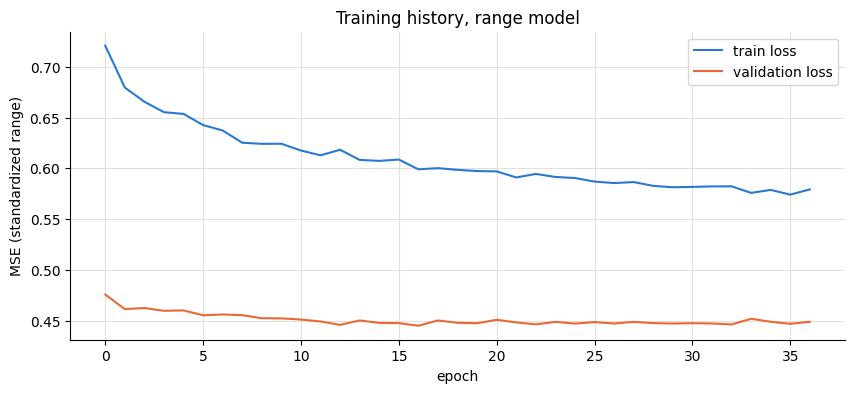

In [94]:
plt.plot(history_range.history["loss"], color=c_nn, label="train loss")
plt.plot(history_range.history["val_loss"], color=c_ar, label="validation loss")
plt.xlabel("epoch")
plt.ylabel("MSE (standardized range)")
plt.title("Training history, range model")
plt.legend()
plt.show()

In [95]:
pred_nn_range = model_range.predict(X_test_range, verbose=0).reshape(len(tickers), -1).T
pred_nn_range = pd.DataFrame(pred_nn_range, index=test_days, columns=tickers)
pred_nn_range = pred_nn_range * trading_range_std + trading_range_mean      # back to raw range

In [96]:
pred_nn_range

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.012631,0.017046,0.014360,0.009777,0.010034,0.009141,0.011411,0.022318,0.010787,0.015469
2024-01-03,0.016205,0.017943,0.015738,0.013242,0.012563,0.011485,0.013934,0.023318,0.010345,0.012163
2024-01-04,0.017560,0.020065,0.017456,0.014147,0.013980,0.011901,0.016121,0.026456,0.011202,0.016896
2024-01-05,0.016366,0.019960,0.016148,0.010757,0.013393,0.010236,0.014232,0.024607,0.011003,0.013632
2024-01-08,0.015482,0.020425,0.016531,0.012216,0.015304,0.012358,0.015933,0.026848,0.012283,0.014160
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.021394,0.028673,0.026233,0.019156,0.017188,0.015161,0.025851,0.051803,0.018940,0.020729
2026-11-17,0.022108,0.028005,0.028491,0.019882,0.022062,0.014851,0.025888,0.052348,0.018508,0.021767
2026-11-18,0.021567,0.028212,0.029025,0.020841,0.022912,0.016194,0.026386,0.069018,0.018931,0.023029


In [97]:
actual_range = trading_range[test_start:test_end]

mse_ar_range = ((actual_range - pred_ar_range) ** 2).mean()
mse_nn_range = ((actual_range - pred_nn_range) ** 2).mean()

results_range = pd.DataFrame({"AR": mse_ar_range / mse_avg, "NN": mse_nn_range / mse_avg})

In [98]:
results_range      # test MSE divided by the 20-day-average baseline MSE, below 1 beats the baseline

,AR,NN
Ticker,,
AAPL,0.761146,0.738916
AMZN,0.796774,0.763819
GOOGL,0.969668,0.918720
JNJ,0.936707,0.894755
JPM,0.884868,0.797196
KO,0.963096,0.885876
MSFT,0.861508,0.807975
NVDA,0.821210,0.811170
WMT,0.847123,0.789794


In [99]:
results_range.mean()

AR    0.872801
NN    0.824199
dtype: float64

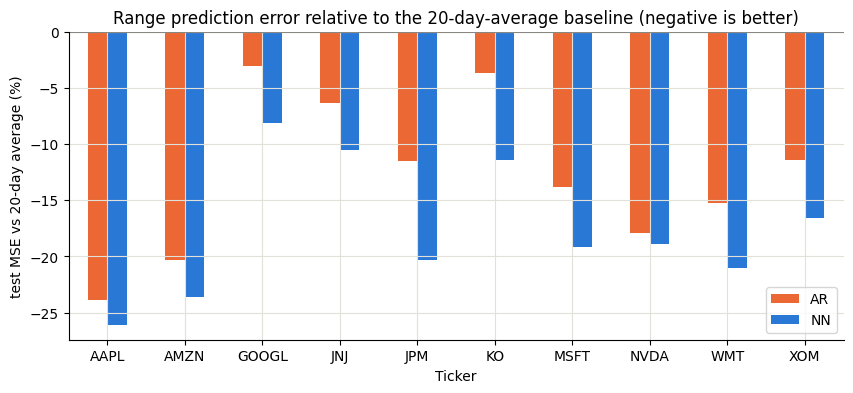

In [100]:
((results_range - 1) * 100).plot.bar(color=[c_ar, c_nn], figsize=(10, 4))
plt.axhline(0, color=c_ref)
plt.ylabel("test MSE vs 20-day average (%)")
plt.title("Range prediction error relative to the 20-day-average baseline (negative is better)")
plt.xticks(rotation=0)
plt.show()

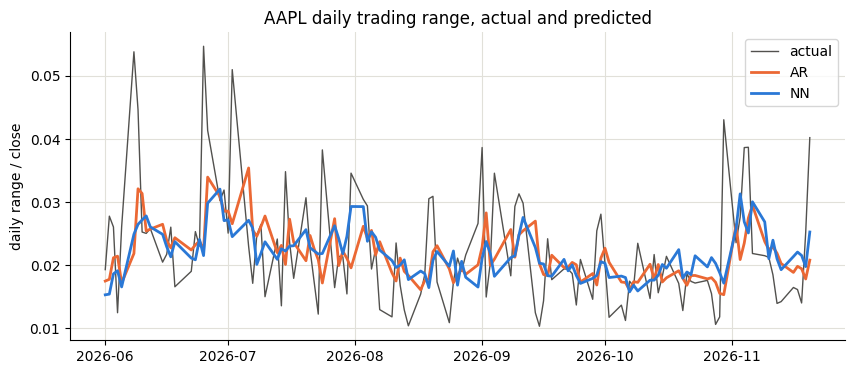

In [101]:
t = "AAPL"

plt.plot(actual_range[t]["2026-06-01":], color=c_actual, linewidth=1, label="actual")
plt.plot(pred_ar_range[t]["2026-06-01":], color=c_ar, linewidth=2, label="AR")
plt.plot(pred_nn_range[t]["2026-06-01":], color=c_nn, linewidth=2, label="NN")
plt.ylabel("daily range / close")
plt.title("AAPL daily trading range, actual and predicted")
plt.legend()
plt.show()